# Audit of high regional forecast probabilities
**Finding:** the website and API use the same numerical probabilities.
The first week has 18/25 departments above 90%; the full issue has
121/300. The department-wide event is frequent, so probabilities often saturate.
**Limitation:** frequencies concern detected episodes, not independently
verified fires. SP-to-NRT transfer and future outcomes remain unvalidated.
**Decision:** retain the frozen model for this audit. Do not reduce
percentages for appearance or select a new calibrator using the same test results.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
repo=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'reports/prediction/probability_audit/audit_summary.json').exists())
folder=repo/'reports/prediction/probability_audit'
summary=json.loads((folder/'audit_summary.json').read_text(encoding='utf-8'))
first=pd.read_csv(folder/'first_week_vs_november_history.csv',dtype={'region_id':str})
bins=pd.read_csv(folder/'historical_calibration_lead1.csv')
figures=repo.parent.parent/'outputs/42_auditoria_probabilidades/figures'
figures.mkdir(parents=True,exist_ok=True)
display(pd.Series({k:summary[k] for k in ['live_rows','live_above_90_percent',
    'first_week_regions_above_90_percent','first_week_total_regions',
    'frozen_model_vs_live_max_absolute_probability_error',
    'historical_positive_frequency','historical_any_detection_frequency',
    'target_new_episode_vs_any_detection_different_region_weeks']},name='result').to_frame())

,result
live_rows,300.000000
live_above_90_percent,121.000000
first_week_regions_above_90_percent,18.000000
first_week_total_regions,25.000000
frozen_model_vs_live_max_absolute_probability_error,0.000000
historical_positive_frequency,0.827130
historical_any_detection_frequency,0.828241
target_new_episode_vs_any_detection_different_region_weeks,12.000000


## 1. Meaning of the probability
A positive outcome means at least one newly detected episode anywhere
in a department during one week. It does not represent
the proportion of detections that are actual fires, the fraction of land
at risk, or a province-level probability. The new-episode proxy and
the presence of any eligible detection differ in only 12 of 10,800 region-weeks.
This target therefore does little to distinguish new physical ignitions from regional activity.

,region_name,probability_percent,historical_november_positive,historical_november_weeks,historical_november_percent
0,AMAZONAS,96.50,33,34,97.06
1,ANCASH,98.07,33,34,97.06
2,APURIMAC,89.02,32,34,94.12
3,AREQUIPA,97.75,34,34,100.00
4,AYACUCHO,94.01,33,34,97.06
5,CAJAMARCA,98.72,34,34,100.00
6,CALLAO,11.07,4,34,11.76
7,CUSCO,97.67,33,34,97.06
8,HUANCAVELICA,87.19,31,34,91.18
9,HUANUCO,97.84,32,34,94.12


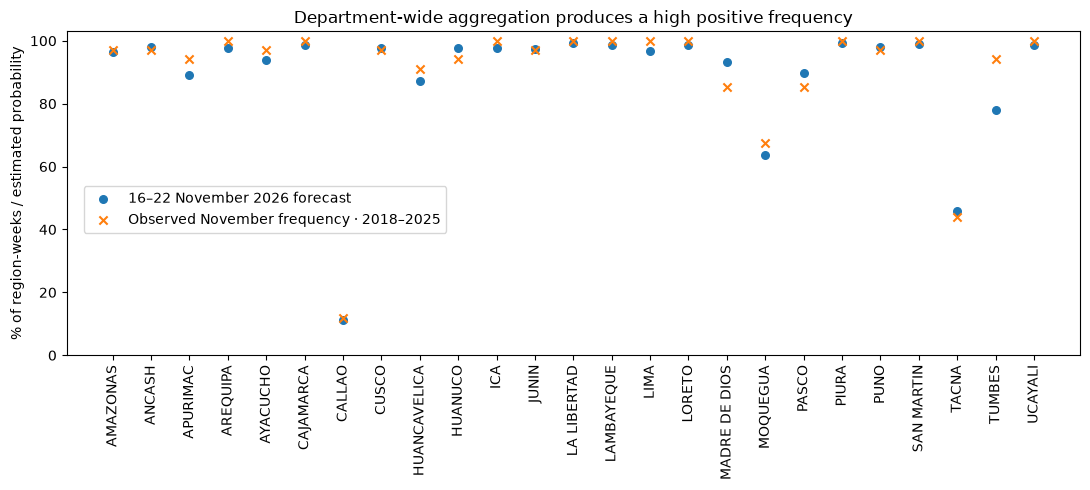

In [2]:
first['historical_november_percent']=100*first.historical_november_frequency
display(first[['region_name','probability_percent','historical_november_positive',
    'historical_november_weeks','historical_november_percent']].round(2))
fig,ax=plt.subplots(figsize=(11,5))
ax.scatter(first.region_name,first.probability_percent,label='16–22 November 2026 forecast',s=30)
ax.scatter(first.region_name,first.historical_november_percent,label='Observed November frequency · 2018–2025',marker='x',s=35)
ax.set_ylabel('% of region-weeks / estimated probability');ax.set_ylim(0,103)
ax.tick_params(axis='x',rotation=90);ax.set_title('Department-wide aggregation produces a high positive frequency')
ax.legend(loc='center left',bbox_to_anchor=(.01,.45));fig.tight_layout();fig.savefig(figures/'regional_base_rate.png',dpi=150);plt.show()

## 2. Historical reliability of the high-probability group
Only lead 1 is used to avoid counting the same target
region-week repeatedly within a period. This is not an evaluation against
confirmed physical fires or a confidence interval for the future target week.
Nearby region-weeks can be correlated. The 2026 observations
end in July; the current issue uses NRT inputs and has no observed outcome yet.

,period,rows,mean_probability,observed_frequency,mean_probability_percent,observed_percent
0,2024,757,0.971,0.985,97.139,98.547
1,2025,756,0.973,0.993,97.268,99.339
2,confirmation_2026,355,0.966,0.983,96.615,98.310


,period,probability_bin,rows,mean_probability,observed_frequency,overprediction_percentage_points
0,2024,0–50 %,190,0.2897,0.2737,1.6064
1,2024,50–80 %,232,0.6713,0.7069,-3.5605
2,2024,80–90 %,121,0.8536,0.8760,-2.2471
3,2024,90–95 %,141,0.9283,0.9504,-2.2044
4,2024,95–99 %,435,0.9763,0.9908,-1.4504
5,2024,99–100 %,181,0.9932,1.0000,-0.6844
6,2025,0–50 %,184,0.2937,0.2554,3.8271
7,2025,50–80 %,214,0.6765,0.6402,3.6323
8,2025,80–90 %,121,0.8515,0.8843,-3.2811
9,2025,90–95 %,129,0.9293,0.9845,-5.5151


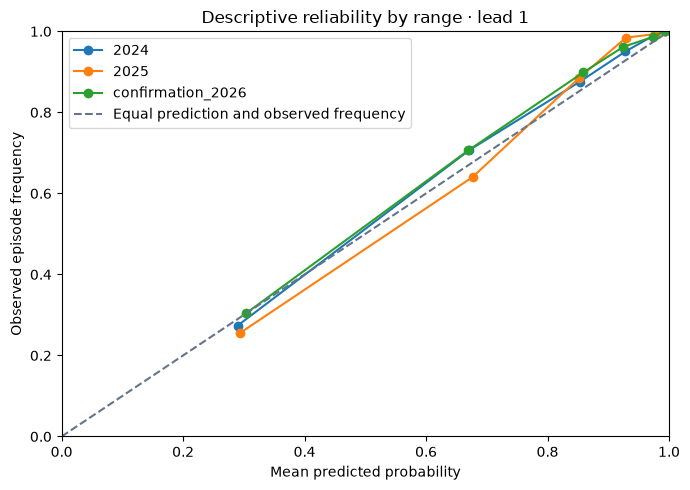

In [3]:
high=pd.read_csv(folder/'historical_high_probability_lead1.csv')
display(high.assign(mean_probability_percent=100*high.mean_probability,
    observed_percent=100*high.observed_frequency).round(3))
display(bins.round(4))
fig,ax=plt.subplots(figsize=(7,5))
for period,g in bins.groupby('period'):
    ax.plot(g.mean_probability,g.observed_frequency,'o-',label=period)
ax.plot([0,1],[0,1],linestyle='--',color='#64748b',label='Equal prediction and observed frequency')
ax.set(xlim=(0,1),ylim=(0,1),xlabel='Mean predicted probability',ylabel='Observed episode frequency',
       title='Descriptive reliability by range · lead 1')
ax.legend();fig.tight_layout();fig.savefig(figures/'high_probability_calibration.png',dpi=150);plt.show()

## 3. Added model signal and remaining validation gaps
Calibrated climatology alone exceeds 90% in 120/300 results,
compared with 121/300 for the model. Region and season dominate the signal;
the saturation is not demonstrably caused by LightGBM alone. The calibration
fitted in 2023 did not improve pooled test performance, and the model ties with climatology
in 2024. These limitations are retained; this audit does not select a new variant.

In [4]:
display(pd.Series({k:summary[k] for k in ['current_calibrated_climatology_above_90_count',
    'current_mean_absolute_model_vs_calibrated_climatology_percentage_points',
    'NRT_SP_transfer_validated','calibration_improvement_demonstrated',
    'physical_ignition_probability_verified','future_outcomes_for_this_snapshot_available',
    'model_changed','public_api_changed']},name='result').to_frame())
outside=pd.read_csv(folder/'current_outside_training_range.csv')
display(outside.groupby('region_id').feature.count().rename('features outside the training range').to_frame())

,result
current_calibrated_climatology_above_90_count,120
current_mean_absolute_model_vs_calibrated_climatology_percentage_points,5.557986
NRT_SP_transfer_validated,False
calibration_improvement_demonstrated,False
physical_ignition_probability_verified,False
future_outcomes_for_this_snapshot_available,False
model_changed,False
public_api_changed,False


,features outside the training range
region_id,
1,7
2,8
3,4
4,4
5,6
6,9
7,2
8,5
9,5


## 4. The website shows Piura while the global filter includes Talara
The supplied production URL was inspected. The page requests region_id=20
and shows 99.2%, matching the rounded API response. It does not request
a province-level model. The province filter should be disabled on this screen or state:
“The forecast covers all of Piura; selecting Talara does not change it.”

In [5]:
website=json.loads((folder/'website_verification.json').read_text(encoding='utf-8'))
display(website)
assert website['display_rounded_to_one_decimal']
assert not website['forecast_request_has_province']
assert not website['numerical_display_bug_found']

{'url': 'https://fuegotrazo-modis-viirs.netlify.app/#pronostico?region=20&prov=2007',
 'department': 'Piura',
 'province_in_page_filter': 'Talara',
 'displayed_first_week_percent': 99.2,
 'API_first_week_percent': 99.16582177703222,
 'display_rounded_to_one_decimal': True,
 'web_uses_probability_percent_directly': True,
 'forecast_request_has_region_id': '20',
 'forecast_request_has_province': False,
 'forecast_scope_explicitly_labeled_department': True,
 'numerical_display_bug_found': False,
 'possible_UX_improvement': 'Disable or explain the province selector on the regional forecast screen.'}

## 5. Recommended product changes and next evaluation
Keep the product explicitly experimental and department-wide. Add
a comparable observed historical frequency to give context
to the percentage. To locate smaller areas of interest, construct labels and
train and evaluate a province- or cell-level model rather than dividing
department probabilities by area. Changing to any eligible fire detection
requires an explicit frozen label and a new evaluation; do not rename the current output
as if the two probabilities were identical. Compare prospectively after each
target week closes and validate SP/NRT transfer before claiming operational reliability.